# Project: Verbs of blinking in WordNet

written by Alina Khurges

Note: I have left some of the "planning" sections from the proposal in, including the original introduction, given again below. Sections prefaced by "**the plan**" are identical to the corresponding step from the proposal.

# General information

For my term paper last year, I did a study on the lexical typology of verbs of blinking and closing the eyes; the study was largely focused on the origins and semantic shifts of these verbs. Verbs of blinking and closing the eyes are verbs such as, for instance, the English verbs *blink*, *wink*, *squint* or the Russian verbs *morgatʹ*, *ščuritʹsja*, *žmuritʹsja*, *podmigivatʹ*. This includes the verbs of closing the eyes briefly, both as an involuntary action (*blink*) and purposefully as a signal (*wink*, if one eye, or *bat one’s eyelashes*, if both), the verbs of closing the eyes partially (*squint*, *half-close* (or *narrow*) *the eyes*), and the verbs of closing the eyes fully (*close the eye*s, or the Russian verb *zažmuritʹsja* ‘close the eyes with force’).

My term paper involved a somewhat experimental approach and was based exclusively on dictionary data (translation dictionaries for 24 languages). This year, in continuing my work on the project, I added data from the CLICS, DatSemShift, and EvoSem databases where possible, but I had not previously considered using WordNet.

So, during this project, I plan to add WordNet data to my work. I plan to investigate the verbs of blinking, squinting, and, if possible, closing the eyes, and see what I can learn about their colexifications from the data of the WordNet database. I expect to see at least some of the colexifications attested in my own work and in the other databases (for instance, a common shift for verbs of blinking is to the meaning of 'twinkling (of light)' (as is the case with the English *blink* or Russian *migatʹ*, *morgatʹ*; I am almost certain that I will find this in WordNet as well), but I am also (and more) interested, of course, in additional occurences of the rarer colexifications in my data, and in novel data.


# The steps



(AI disclosure: the AI DeepSeek was consulted in the process of debugging the code, adjusting the graphs to be more readable, and splitting into communities)

As "Step 0", I actually access WordNet (and check the languages)

In [1]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [2]:
nltk.download('omw-1.4')

[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
from nltk.corpus import wordnet as wn

In [4]:
wn.add_omw()

In [5]:
sorted(wn.langs())

['als',
 'arb',
 'bul',
 'cat',
 'cmn',
 'dan',
 'ell',
 'eng',
 'eus',
 'fin',
 'fra',
 'glg',
 'heb',
 'hrv',
 'ind',
 'isl',
 'ita',
 'ita_iwn',
 'jpn',
 'lit',
 'nld',
 'nno',
 'nob',
 'pol',
 'por',
 'ron',
 'slk',
 'slv',
 'spa',
 'swe',
 'tha',
 'zsm']

## Step 1

**The plan:** Find out which WordNet synsets correspond to the relevant meanings. From a cursory search (looking up the synsets that have a substring 'wink', 'blink', 'squint', 'bat' and then going through their definitions; I suppose I would need to go through other synsets that have 'wink', 'blink', or 'squint' in the name as well), these seem to be at least the following: 'blink.v.01' ('briefly shut the eyes'), 'wink.v.01' ('signal by winking'), 'wink.v.03' ('briefly shut the eyes'), 'bat.v.02' ('wink briefly') for the verbs of blinking, 'squint.v.03' ('partly close one's eyes, as when hit by direct blinding light') for the verbs of squinting. I am not yet certain whether I will be able to acquire data for the verbs of closing the eyes specifically, since (again, based on a cursory search) there does not seem to be a corresponding synset for this specific meaning. Japanese, which is in the WordNet language set and also in my original sample, has eye-specific closing verbs; I might want to investigate which synsets they belong to, if they are attested in WordNet at all, and perhaps investigate those synsets in a preliminary fashion.

Looking for relevant synsets and deciding what to include:

In [6]:
for s in (wn.synsets('blink', pos=wn.VERB)):
  print(s.name(), s.definition())

blink.v.01 briefly shut the eyes
wink.v.04 force to go away by blinking
flash.v.01 gleam or glow intermittently


blink.v.01 (core meaning); wink.v.04 (I hesitated, but decided to include it)

In [7]:
for s in (wn.synsets('wink', pos=wn.VERB)):
  print(s.name(), s.definition())

wink.v.01 signal by winking
flash.v.01 gleam or glow intermittently
blink.v.01 briefly shut the eyes
wink.v.04 force to go away by blinking


wink.v.01

In [8]:
for s in (wn.synsets('squint', pos=wn.VERB)):
  print(s.name(), s.definition())

squint.v.01 cross one's eyes as if in strabismus
squint.v.02 be cross-eyed; have a squint or strabismus
squint.v.03 partly close one's eyes, as when hit by direct blinding light


Only squint.v.03

In [9]:
for s in (wn.synsets('bat', pos=wn.VERB)):
  print(s.name(), s.definition())

bat.v.01 strike with, or as if with a baseball bat
bat.v.02 wink briefly
bat.v.03 have a turn at bat
bat.v.04 use a bat
cream.v.02 beat thoroughly and conclusively in a competition or fight


Only bat v.02

There is no separate synset for the meaning "close the eyes":

In [10]:
for s in (wn.synsets('close', pos=wn.VERB)):
  print(s.name(), s.definition())

close.v.01 move so that an opening or passage is obstructed; make shut
close.v.02 become closed
close_up.v.01 cease to operate or cause to cease operating
close.v.04 finish or terminate (meetings, speeches, etc.)
conclude.v.04 come to a close
close.v.06 complete a business deal, negotiation, or an agreement
close.v.07 be priced or listed when trading stops
close.v.08 engage at close quarters
close.v.09 cause a window or an application to disappear on a computer desktop
close.v.10 change one's body stance so that the forward shoulder and foot are closer to the intended point of impact
close.v.11 come together, as if in an embrace
close.v.12 draw near
close.v.13 bring together all the elements or parts of
close.v.14 bar access to
close.v.15 fill or stop up
close_up.v.03 unite or bring into contact or bring together the edges of
close.v.17 finish a game in baseball by protecting a lead


I checked a Japanese eye-specific closing verb:

In [11]:
# lookup of a japanese verb meaning 'to close the eyes'
for s in (wn.synsets('瞑る', lang="jpn")):
  print(s.name(), s.definition())

close.v.01 move so that an opening or passage is obstructed; make shut


So, if any synsets related to closing are to be included, it is 'close.v.01'

In [12]:
# I checked wink.v.03 as well
print(wn.synset('wink.v.03').definition())
wn.synset('wink.v.03').lemmas()
# confusing... I decided to include it just in case

briefly shut the eyes


[Lemma('blink.v.01.blink'),
 Lemma('blink.v.01.wink'),
 Lemma('blink.v.01.nictitate'),
 Lemma('blink.v.01.nictate')]

I decided to exclude the verbs of closing for the main project, and include only the verbs of blinking and squinting:

In [6]:
relevant_list = ['blink.v.01', 'wink.v.01', 'wink.v.04', 'squint.v.03', 'bat.v.02', 'wink.v.03']

(Just in case, the same with the closing synset included)

In [7]:
relevant_list2 = ['blink.v.01', 'wink.v.01', 'wink.v.04', 'squint.v.03', 'bat.v.02', 'wink.v.03', 'close.v.01']

(If you include 'close.v.01', because the closing domain is obviously larger than the blinking domain, closing verbs of various sorts end up overwhelming the graph; for this reason, I excluded them; I do return to them in step 5)

## Step 2

**The plan**: Extract the lemmas belonging to each of the identified synsets for all the languages in the database. Collect the "lemma : [list of synsets]" correspondences.

My original plan was to use every occurring synset as a node in the graph; I decided to use those with at least two occurrences to make the graph more readable.

In [9]:
lemmas_by_lang = {}
for lang in wn.langs():
  lemmas_total = []
  for s in relevant_list:
    lemmas = [l.name() for l in wn.synset(s).lemmas(lang=lang)]
    if lemmas:  # only the non-empty ones
      lemmas_total.extend(sorted(set(lemmas)))
    lemmas_by_lang[lang] = sorted(set(lemmas_total))
len(lemmas_by_lang)


32

In [10]:
lemma2synsets = {}
for lang, lemmas in lemmas_by_lang.items():
  for lemma in lemmas:
    lemma2synsets[(lang, lemma)] = wn.synsets(lemma, lang=lang)
len(lemma2synsets)
# print(lemma2synsets)

122

In [11]:
synset_support = {} # Synset --> set of (lang, lemma)
for key, synsets in lemma2synsets.items():
  for s in synsets:
    synset_support.setdefault(s, set()).add(key)
print(len(synset_support))
# print(synset_support)

94


I tested whether I should limit the synsets included to only those with a larger number of occurrences; limiting it to things with more than two ocurrences seems too restrictive:

In [19]:

selected_synsets = sorted(
    [s for s, keys in synset_support.items() if len(keys) > 2],
    key=lambda s: s.name()
)
print(len(selected_synsets))
print(selected_synsets)

16
[Synset('bat.v.02'), Synset('blink.n.01'), Synset('blink.v.01'), Synset('dart.v.02'), Synset('flash.v.01'), Synset('flicker.v.01'), Synset('flicker.v.02'), Synset('flicker.v.03'), Synset('palpebrate.v.01'), Synset('spangle.v.01'), Synset('sparkle.v.01'), Synset('squint.v.02'), Synset('squint.v.03'), Synset('twinkle.v.02'), Synset('wink.v.01'), Synset('wink.v.04')]


Including every single one would make the graph harder to read:

In [14]:
selected_synsets = sorted([s for s, keys in synset_support.items()],
                          key=lambda s: s.name())
print(len(selected_synsets))
print(selected_synsets)

94
[Synset('act.v.02'), Synset('askance.s.01'), Synset('authorize.v.01'), Synset('bat.n.01'), Synset('bat.n.02'), Synset('bat.n.05'), Synset('bat.v.01'), Synset('bat.v.02'), Synset('bat.v.03'), Synset('bat.v.04'), Synset('bate.v.02'), Synset('beat.v.08'), Synset('beat.v.15'), Synset('blink.n.01'), Synset('blink.v.01'), Synset('blink_of_an_eye.n.01'), Synset('blinking.s.01'), Synset('cause.v.01'), Synset('chiroptera.n.01'), Synset('choke.v.04'), Synset('clap.v.02'), Synset('communicate.v.01'), Synset('complete.v.01'), Synset('cream.v.02'), Synset('cricket_bat.n.01'), Synset('dart.v.02'), Synset('decide.v.01'), Synset('determine.v.01'), Synset('die.v.01'), Synset('disturbance.n.03'), Synset('do.v.03'), Synset('drown.v.02'), Synset('drown.v.04'), Synset('drown_out.v.01'), Synset('elapse.v.01'), Synset('end.v.01'), Synset('end.v.02'), Synset('evanesce.v.01'), Synset('flap.n.03'), Synset('flare.v.01'), Synset('flare.v.03'), Synset('flash.v.01'), Synset('flash.v.02'), Synset('flash.v.04'), S

(That being said: I think it would be worthwhile to inspect these single-instance colexifications; some of them are clearly noise ('chiroptera.n.01' is because of *bat* English homonymy, see below), but some of them align with my own data ('blink_of_an_eye.n.01', for instance)

In [36]:
wn.synset("chiroptera.n.01").definition()

'an old order dating to early Eocene: bats: suborder Megachiroptera (fruit bats); suborder Microchiroptera (insectivorous bats)'

In [37]:
wn.synset("blink_of_an_eye.n.01").definition()
# in my own work I was not collecting nouns purposefully, merely noting them when I saw them
# but nouns with this sense derived from blinking verbs do appear in dictionaries; cf. Russian мгновение etc

'a very short time (as the time it takes the eye to blink or the heart to beat)'

I think limiting them to those with at least two occurrences is the best option:

In [30]:
selected_synsets = sorted(
    [s for s, keys in synset_support.items() if len(keys) > 1],
    key=lambda s: s.name())
print(len(selected_synsets))
print(selected_synsets)

42
[Synset('bat.n.01'), Synset('bat.n.02'), Synset('bat.n.05'), Synset('bat.v.01'), Synset('bat.v.02'), Synset('bat.v.03'), Synset('bat.v.04'), Synset('beat.v.08'), Synset('beat.v.15'), Synset('blink.n.01'), Synset('blink.v.01'), Synset('blinking.s.01'), Synset('cream.v.02'), Synset('cricket_bat.n.01'), Synset('dart.v.02'), Synset('flash.v.01'), Synset('flash.v.02'), Synset('flash.v.04'), Synset('flaunt.v.01'), Synset('flicker.v.01'), Synset('flicker.v.02'), Synset('flicker.v.03'), Synset('flickering.s.01'), Synset('flutter.v.03'), Synset('foam.v.01'), Synset('gleam.v.02'), Synset('gutter.v.01'), Synset('ogle.v.01'), Synset('palpebrate.v.01'), Synset('spangle.v.01'), Synset('spangle.v.02'), Synset('spark.v.02'), Synset('sparkle.v.01'), Synset('squash_racket.n.01'), Synset('squint.v.01'), Synset('squint.v.02'), Synset('squint.v.03'), Synset('twinkle.n.01'), Synset('twinkle.v.02'), Synset('twinkling.s.01'), Synset('wink.v.01'), Synset('wink.v.04')]


I inspected the resulting synsets and their definitions:

In [31]:
selected_sorted = sorted(selected_synsets, key=lambda s: len(synset_support[s]), reverse=True)
for s in selected_sorted:
    print(s.name(), len(synset_support[s]), "-", s.definition())

blink.v.01 65 - briefly shut the eyes
wink.v.01 30 - signal by winking
wink.v.04 25 - force to go away by blinking
bat.v.02 24 - wink briefly
flash.v.01 22 - gleam or glow intermittently
flicker.v.01 13 - move back and forth very rapidly
squint.v.03 10 - partly close one's eyes, as when hit by direct blinding light
twinkle.v.02 8 - emit or reflect light in a flickering manner
blink.n.01 7 - a reflex that closes and opens the eyes rapidly
flicker.v.02 6 - shine unsteadily
palpebrate.v.01 6 - wink or blink, especially repeatedly
flicker.v.03 5 - flash intermittently
dart.v.02 3 - run or move very quickly or hastily
spangle.v.01 3 - glitter as if covered with spangles
sparkle.v.01 3 - reflect brightly
squint.v.02 3 - be cross-eyed; have a squint or strabismus
bat.n.01 2 - nocturnal mouselike mammal with forelimbs modified to form membranous wings and anatomical adaptations for echolocation by which they navigate
bat.n.02 2 - (baseball) a turn trying to get a hit
bat.n.05 2 - a club used f

A problem: many of the "bat" senses are probably only there because of English homonymy; let us check in what languages the suspicious senses appear:

In [16]:
suspicious = ['bat.n.01', 'bat.n.02', 'bat.n.05', 'bat.v.01', 'bat.v.03', 'bat.v.04', 'cream.v.02', 'cricket_bat.n.01', 'squash_racket.n.01']

# Build a lookup: lemma string -> set of synset names in selected_synsets

lemma_to_selected = {}
for synset in selected_synsets:
    for lang in wn.langs():
        for lemma in synset.lemmas(lang):
            lemma_to_selected.setdefault(lemma.name(), set()).add(synset.name())

# For each suspicious synset, find lemmas that also appear in selected_synsets
for s_name in suspicious:
    try:
        synset = wn.synset(s_name)
    except Exception as e:
        print(f"Could not load {s_name}: {e}")
        continue

    print(f"\n=== {s_name} ({synset.definition()}) ===")
    found_any = False
    for lang in wn.langs():
        for lemma in synset.lemmas(lang):
            shared = lemma_to_selected.get(lemma.name(), set())
            # Exclude the synset itself
            shared = {x for x in shared if x != s_name}
            if shared:
                found_any = True
                print(f"  [{lang}] '{lemma.name()}' also in: {sorted(shared)}")
    if not found_any:
        print("  (no shared lemmas with selected_synsets)")


=== bat.n.01 (nocturnal mouselike mammal with forelimbs modified to form membranous wings and anatomical adaptations for echolocation by which they navigate) ===
  [eng] 'bat' also in: ['bat.n.02', 'bat.n.05', 'bat.v.01', 'bat.v.02', 'bat.v.03', 'bat.v.04', 'cream.v.02', 'cricket_bat.n.01', 'squash_racket.n.01']
  [fra] 'chauve-souris' also in: ['bat.n.02', 'bat.n.05', 'bat.v.01', 'bat.v.02', 'bat.v.03', 'bat.v.04', 'chiroptera.n.01', 'cream.v.02', 'cricket_bat.n.01', 'squash_racket.n.01']
  [spa] 'chiroptera' also in: ['chiroptera.n.01']

=== bat.n.02 ((baseball) a turn trying to get a hit) ===
  [eng] 'bat' also in: ['bat.n.01', 'bat.n.05', 'bat.v.01', 'bat.v.02', 'bat.v.03', 'bat.v.04', 'cream.v.02', 'cricket_bat.n.01', 'squash_racket.n.01']
  [fra] 'chauve-souris' also in: ['bat.n.01', 'bat.n.05', 'bat.v.01', 'bat.v.02', 'bat.v.03', 'bat.v.04', 'chiroptera.n.01', 'cream.v.02', 'cricket_bat.n.01', 'squash_racket.n.01']

=== bat.n.05 (a club used for hitting a ball in various games)

It seems like all of these are irrelevant!

Let us remove them:

In [32]:
selected_synsets = [s for s in selected_synsets if s.name() not in suspicious]

In [33]:
print(selected_synsets)
print(len(selected_synsets))

[Synset('bat.v.02'), Synset('beat.v.08'), Synset('beat.v.15'), Synset('blink.n.01'), Synset('blink.v.01'), Synset('blinking.s.01'), Synset('dart.v.02'), Synset('flash.v.01'), Synset('flash.v.02'), Synset('flash.v.04'), Synset('flaunt.v.01'), Synset('flicker.v.01'), Synset('flicker.v.02'), Synset('flicker.v.03'), Synset('flickering.s.01'), Synset('flutter.v.03'), Synset('foam.v.01'), Synset('gleam.v.02'), Synset('gutter.v.01'), Synset('ogle.v.01'), Synset('palpebrate.v.01'), Synset('spangle.v.01'), Synset('spangle.v.02'), Synset('spark.v.02'), Synset('sparkle.v.01'), Synset('squint.v.01'), Synset('squint.v.02'), Synset('squint.v.03'), Synset('twinkle.n.01'), Synset('twinkle.v.02'), Synset('twinkling.s.01'), Synset('wink.v.01'), Synset('wink.v.04')]
33


## Step 3

Make a weighted graph where the edges correspond to colexifications of the two meanings.

In [34]:
selected_set = set(selected_synsets)

In [35]:
synset2lemmas = {}
for s in selected_synsets:
    L = set()
    for lang in wn.langs():
        for l in s.lemmas(lang=lang):
            L.add((lang, l.name()))
    synset2lemmas[s] = L
# sanity check
some = selected_synsets[0]
print(len(synset2lemmas[some]))
print(synset2lemmas[some])

24
{('eus', 'kliskatu'), ('zsm', 'mengedipkan'), ('eng', 'flutter'), ('tha', 'ขยิบตา'), ('eng', 'bat'), ('ind', 'mengedipkan'), ('jpn', 'パチパチ+する'), ('jpn', '瞬く'), ('jpn', 'しばたく'), ('lit', 'mirktelėti'), ('fin', 'räpytellä'), ('ron', 'batedingene'), ('spa', 'aletear'), ('ron', 'zbategenele'), ('zsm', 'mengelipkan'), ('fra', 'chauve-souris'), ('cat', 'parpellejar'), ('zsm', 'mengejapkan'), ('cmn', '眨眼'), ('slk', 'žmurkať'), ('fin', 'vinkata'), ('spa', 'pestañear'), ('ind', 'mengejapkan'), ('jpn', 'しばたたく')}


In [42]:
edges = {}
nodes = list(selected_synsets)
for i in range(len(nodes)):
    s1 = nodes[i]
    for j in range(i+1, len(nodes)):
        s2 = nodes[j]
        inter = synset2lemmas[s1].intersection(synset2lemmas[s2])
        w = len(inter)
        if w > 0:
            edges[(s1, s2)] = w
len(edges)

161

In [ ]:
!pip install networkx

In [22]:
import networkx as nx

In [43]:
G = nx.Graph()

In [44]:
for s in selected_synsets:
  G.add_node(s)
for (s1, s2), w in edges.items():
    G.add_edge(s1, s2, weight=w)

print(G.number_of_nodes(), G.number_of_edges())

33 161


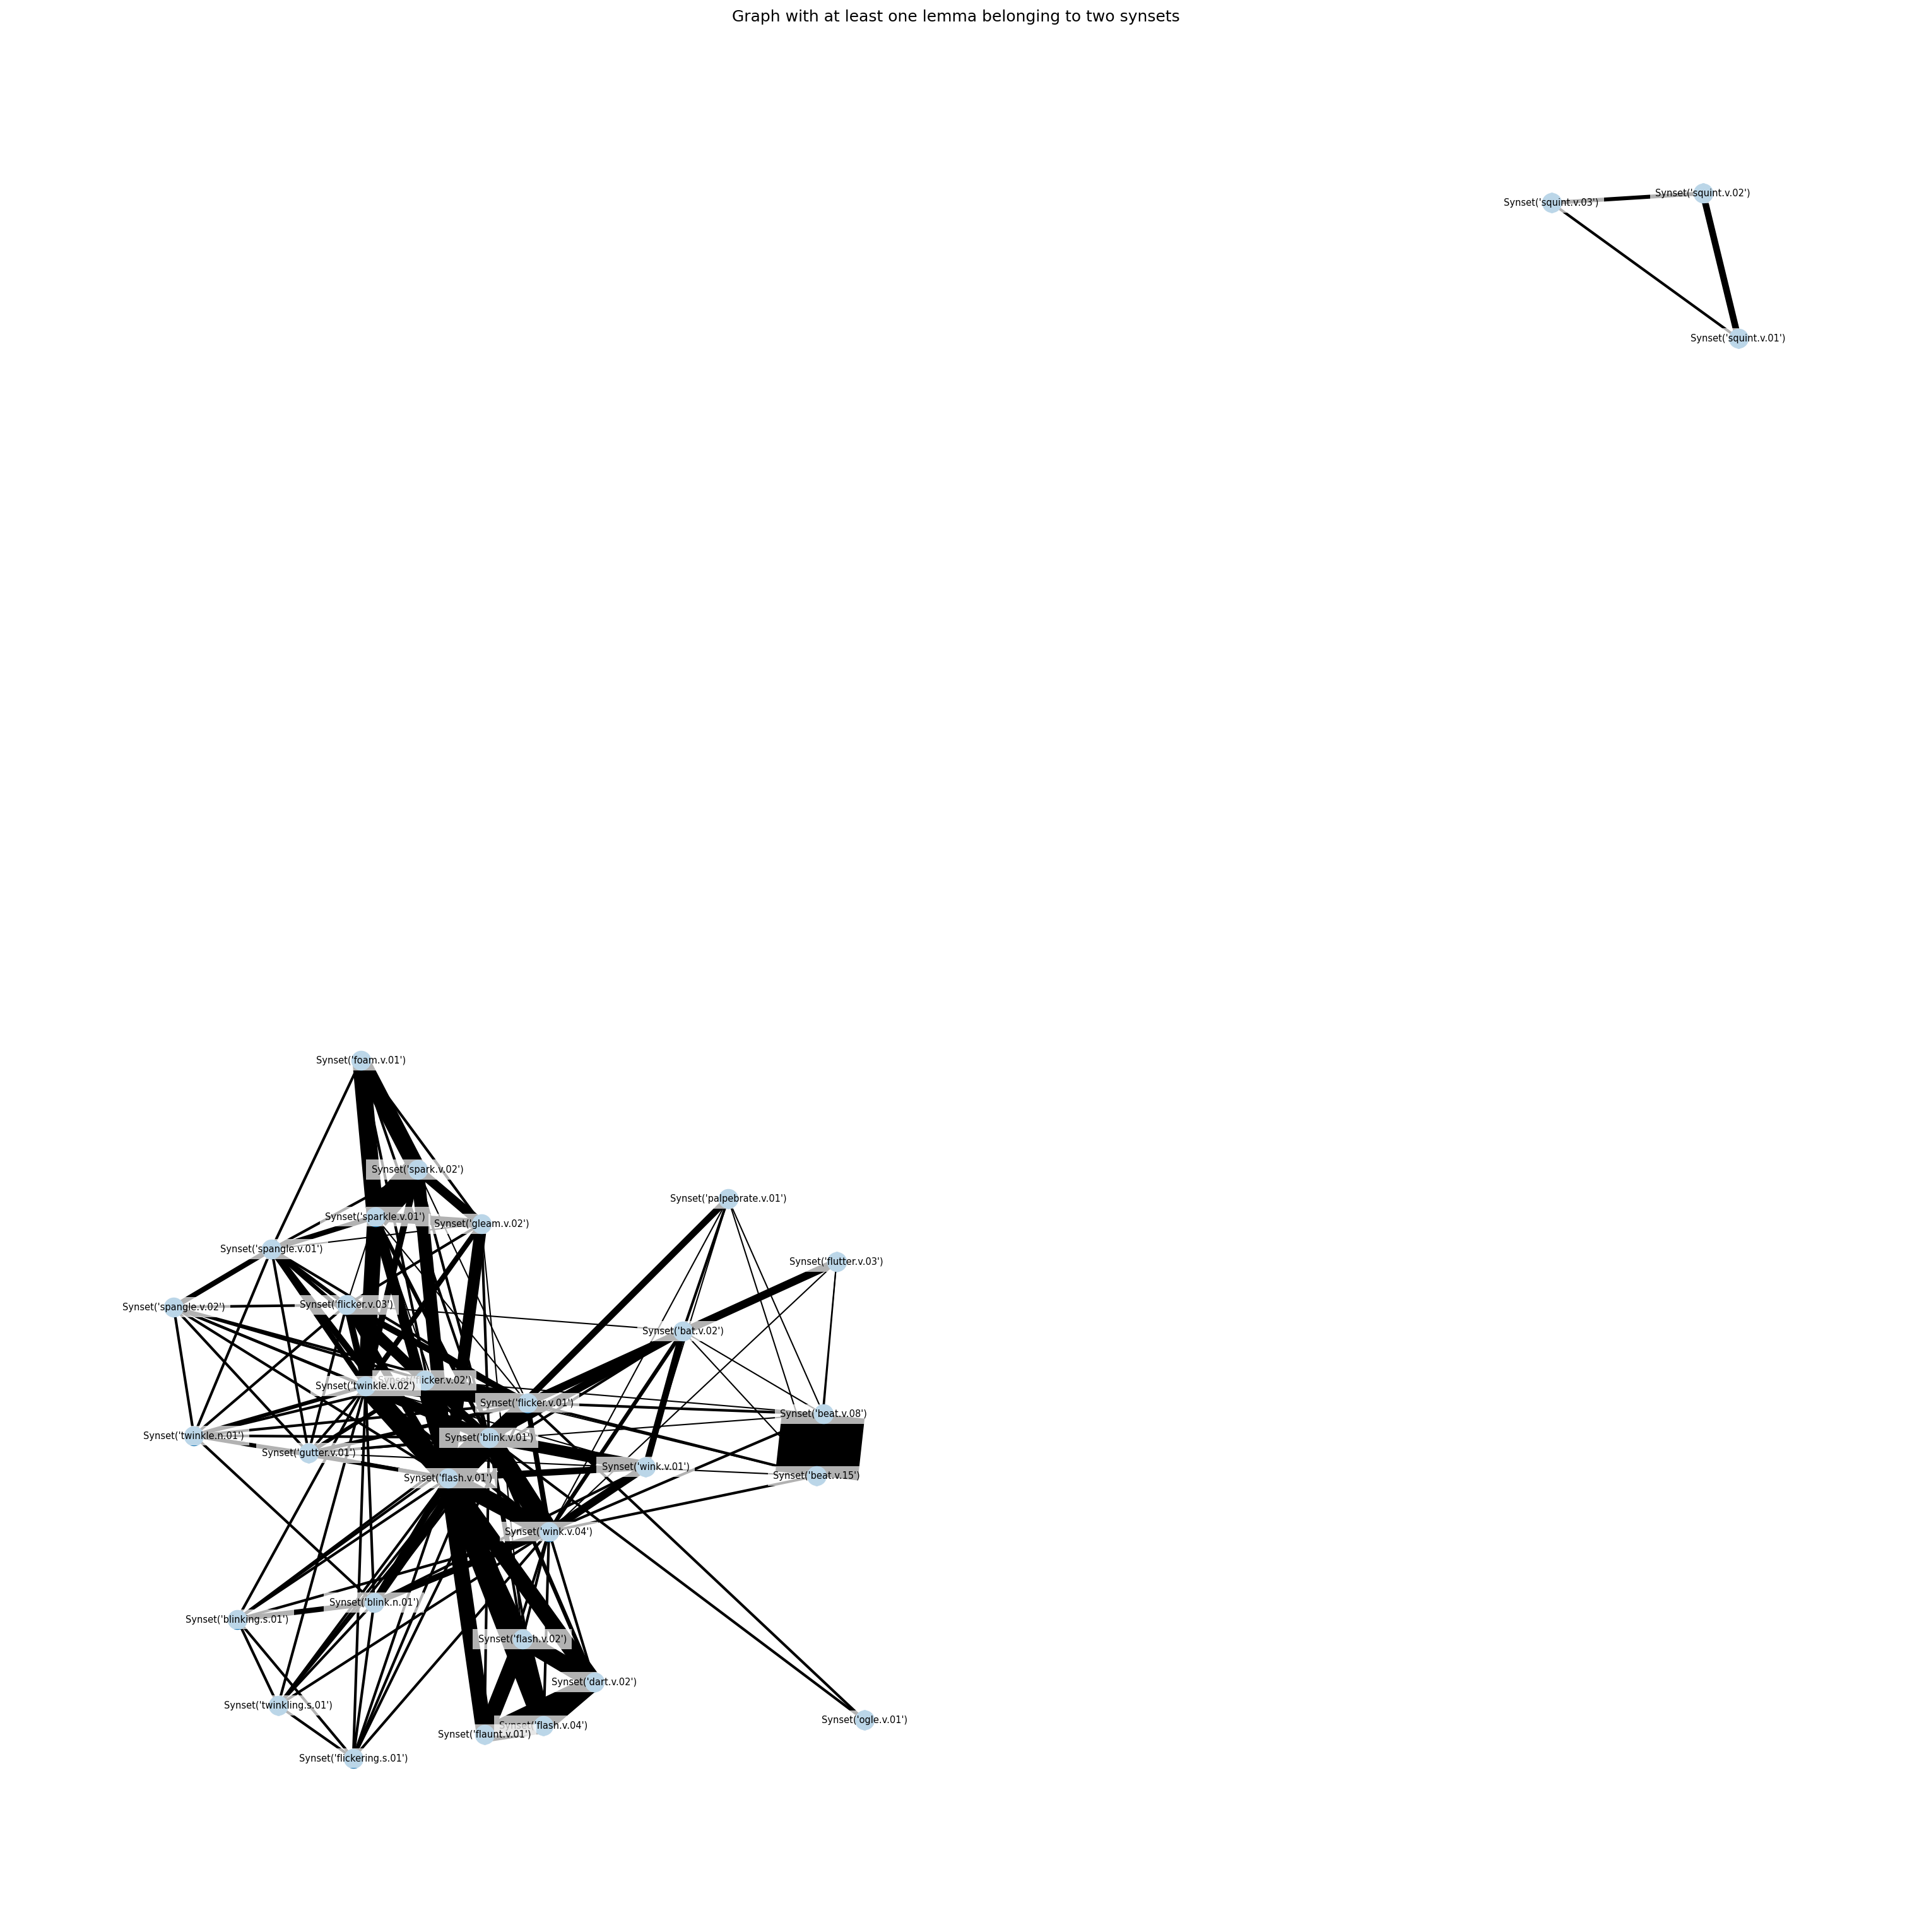

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 20), dpi=150)
pos = nx.spring_layout(G, k=0.5, iterations=50, scale=2.0, seed=42)

weights = [G[u][v]['weight'] for u, v in G.edges()]

nx.draw(G, pos,
        node_size=200,
       width=weights)
nx.draw_networkx_labels(G, pos, font_size=7,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

plt.title("Graph with at least one lemma belonging to two synsets")
plt.show()

Or an alternative with a different layout:

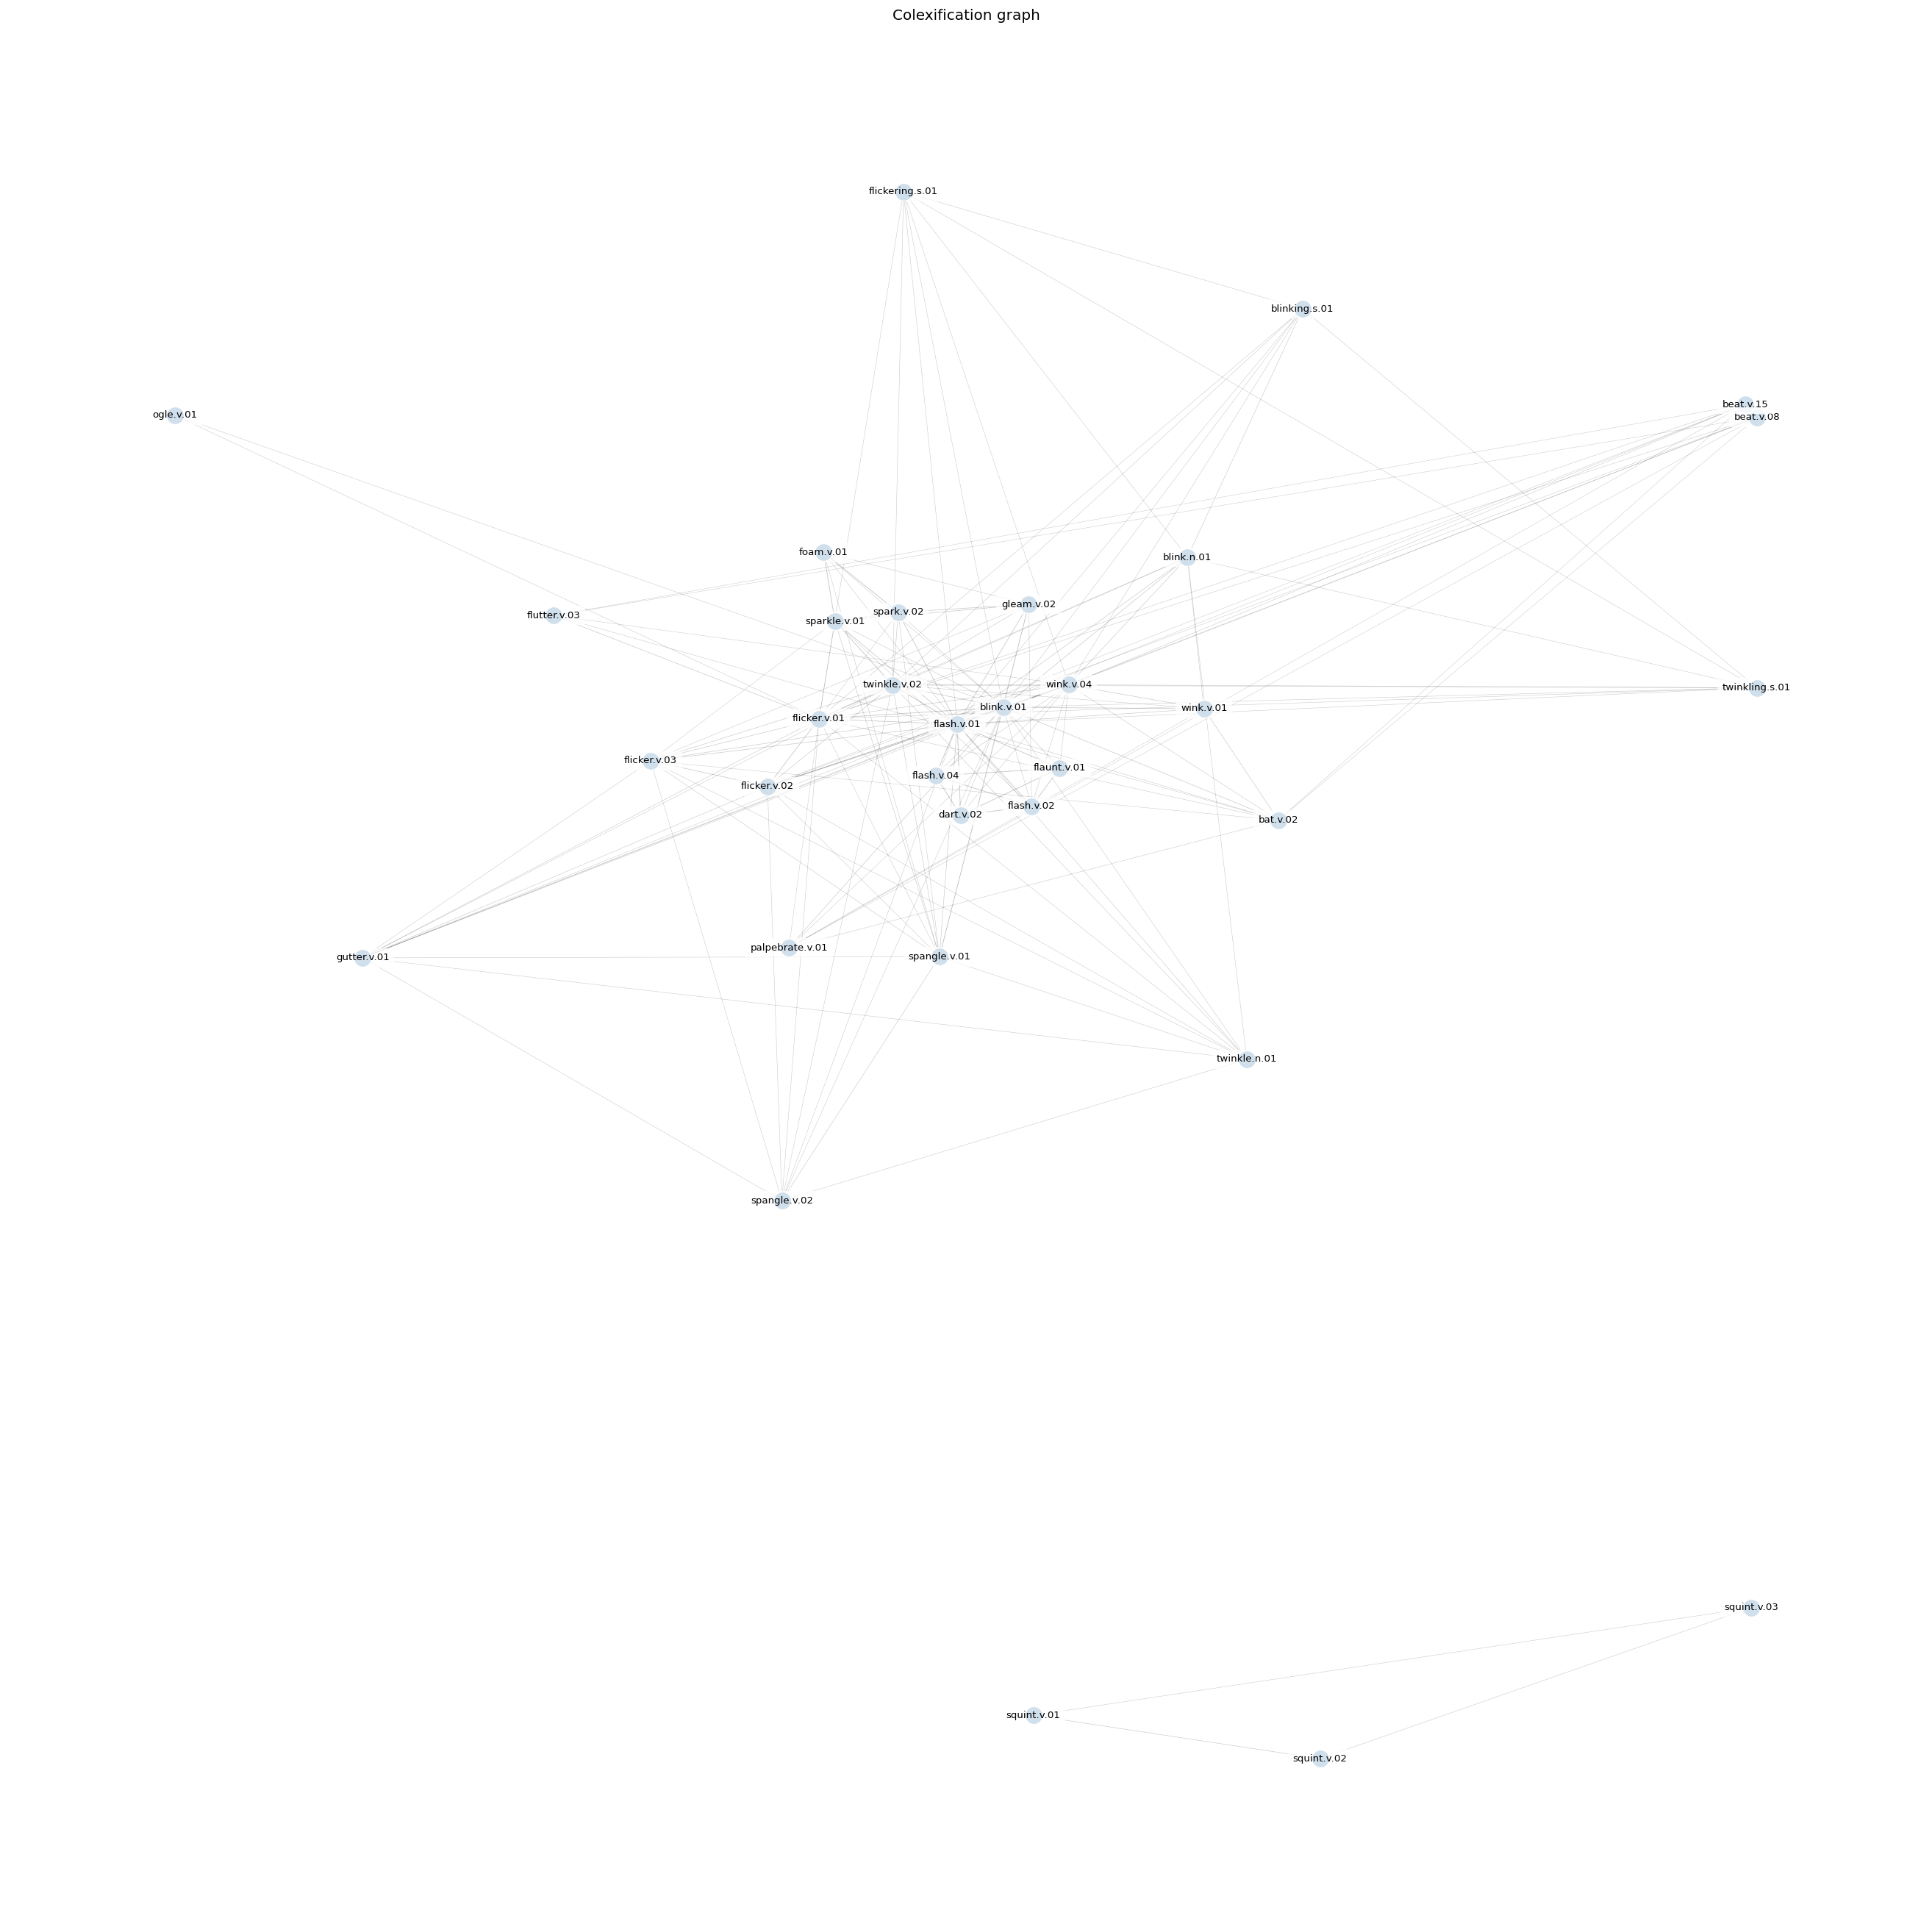

In [74]:
import numpy as np

G_str = nx.relabel_nodes(G, {n: n.name() for n in G.nodes()})

for u, v, d in G_str.edges(data=True):
    d['inv_weight'] = 1.0 / d['weight']

pos3 = nx.kamada_kawai_layout(G_str, weight='inv_weight')

weights = np.array([G_str[u][v]['weight'] for u, v in G_str.edges()])
widths = 0.3 + 1.5 * (weights / weights.max())

fig, ax = plt.subplots(figsize=(22, 22), dpi=120)
nx.draw_networkx_edges(G_str, pos3, ax=ax, width=widths, alpha=0.2)
nx.draw_networkx_nodes(G_str, pos3, ax=ax, node_size=200,
                       node_color='steelblue', edgecolors='white', linewidths=0.5)
nx.draw_networkx_labels(G_str, pos3, font_size=8,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.75))
ax.set_title("Colexification graph")
ax.axis('off')
plt.tight_layout()
plt.show()

In [66]:
print("neighbors of 'dart.v.02':", list(G_str.neighbors('dart.v.02')))
print("neighbors of 'flaunt.v.01':",list(G_str.neighbors('flaunt.v.01')))
print("neighbors of ogle.v.01':", list(G_str.neighbors('ogle.v.01')))
print("neighbors of 'beat.v.15':",list(G_str.neighbors('beat.v.15')))
print("neighbors of beat.v.08';", list(G_str.neighbors('beat.v.08')))
print("neighbors of 'foam.v.01':", list(G_str.neighbors('foam.v.01')))

neighbors of 'dart.v.02': ['blink.v.01', 'flash.v.01', 'flash.v.02', 'flash.v.04', 'flaunt.v.01', 'wink.v.04']
neighbors of 'flaunt.v.01': ['blink.v.01', 'dart.v.02', 'flash.v.01', 'flash.v.02', 'flash.v.04', 'wink.v.04']
neighbors of ogle.v.01': ['blink.v.01', 'flicker.v.01']
neighbors of 'beat.v.15': ['bat.v.02', 'beat.v.08', 'flicker.v.01', 'flicker.v.02', 'flutter.v.03', 'gutter.v.01', 'palpebrate.v.01', 'wink.v.04']
neighbors of beat.v.08'; ['bat.v.02', 'beat.v.15', 'flicker.v.01', 'flicker.v.02', 'flutter.v.03', 'gutter.v.01', 'palpebrate.v.01', 'wink.v.04']
neighbors of 'foam.v.01': ['blink.v.01', 'flash.v.01', 'gleam.v.02', 'spangle.v.01', 'spark.v.02', 'sparkle.v.01']


Notes on the graph itself:
* a lot of very particularly described meanings related to light that I, in my own work, grouped together as 'flash, flicker, twinkle'; much more nuance than my own description (WordNet distinguishes 'flash' from 'flicker' from 'twinkle' from 'shine' and so on, I simply group all of these light-connected meanings together)
* familiar rarer meanings: 'beat' being colexified with 'blink' occurs in my own data; 'flutter' is familiar as well
* novel meanings: 'dart', 'flaunt', 'foam'
* possibly novel: 'ogle' (I did not include verbs of looking in various ways in my work at all)

## Step 4

**The plan:**
Perform network analysis:
* measure the density (is everything colexified with everything else? probably not; but I do not have particular expectations on how dense it is going to be)
* check the number of components (would the graph for the blinking verbs, which started from me collecting all the lemmas for several synsets, have several components? the graph for squinting verbs should have only one component by design)
* identify the nodes with the highest weighted degree (approximately the meanings that are colexified with other meanings the most in the most languages)
* identify the nodes with the highest betweenness centrality (approximately the central nodes if also high in weighted degree, and "bridges" between different parts of the graph if not)
* split the graph into communities (I am not yet entirely certain which algorithm I should choose; possibly one that would take the fact that the graph is weighted into account somehow?).

Comment on the similarity of the results to the results previously obtained in my work (for instance, which of the colexifications that I have previously observed appear? are there any new ones?).

Checking the number of components:

In [28]:
components = list(nx.connected_components(G))
sorted([len(c) for c in components], reverse=True)
print(len(components))

2


I ended up including the verbs of blinking and squinting on the same graph; however, they ended up being separate components (all the verbs of blinking, as expected, ended up forming one component). This is interesting: blinking and squinting were colexified several times in my data, but apparently no such colexifications appear in the WordNet database. (In my data, verbs of squinting are found in less dictionaries than verbs of blinking (some dictionaries simply do not include them); they are rarer in the other databases as well; perhaps this is also the case in WordNet, and this is why we do not see the colexification)

Checking the density:

In [47]:
nx.density(G)

0.30492424242424243

The graph is comparatively dense; not everything is colexified with everything else, but it is not very sparse either.

Showing the synsets with the highest degree:

In [48]:
degree_dict = dict(G.degree())
sorted(degree_dict.items(), key=lambda x: x[1], reverse=True)[:10]

[(Synset('blink.v.01'), 26),
 (Synset('flash.v.01'), 24),
 (Synset('flicker.v.01'), 22),
 (Synset('wink.v.04'), 19),
 (Synset('twinkle.v.02'), 18),
 (Synset('spangle.v.01'), 13),
 (Synset('flicker.v.02'), 12),
 (Synset('flicker.v.03'), 12),
 (Synset('gutter.v.01'), 11),
 (Synset('bat.v.02'), 10)]

And the highest weighted degree:

In [49]:
weighted_degree = dict(G.degree(weight='weight'))
sorted(weighted_degree.items(), key=lambda x: x[1], reverse=True)[:10]

[(Synset('flash.v.01'), 182),
 (Synset('blink.v.01'), 128),
 (Synset('twinkle.v.02'), 85),
 (Synset('flicker.v.01'), 82),
 (Synset('beat.v.08'), 72),
 (Synset('beat.v.15'), 72),
 (Synset('sparkle.v.01'), 71),
 (Synset('wink.v.04'), 71),
 (Synset('spark.v.02'), 61),
 (Synset('flash.v.02'), 55)]

In [50]:
import numpy as np

deg_values = list(degree_dict.values())
wdeg_values = list(weighted_degree.values())

print("Degree:")
print("min:", np.min(deg_values))
print("max:", np.max(deg_values))
print("mean:", np.mean(deg_values))

print("\nWeighted degree:")
print("min:", np.min(wdeg_values))
print("max:", np.max(wdeg_values))
print("mean:", np.mean(wdeg_values))

Degree:
min: 2
max: 26
mean: 9.757575757575758

Weighted degree:
min: 4
max: 182
mean: 44.96969696969697


The synsets with the highest betweenness centrality:

In [52]:
b = nx.betweenness_centrality(G) # how many paths go through a node
for nodeid in sorted(b, key=b.get, reverse=True)[:10]:
    print(nodeid)

Synset('blink.v.01')
Synset('flash.v.01')
Synset('flicker.v.01')
Synset('wink.v.04')
Synset('twinkle.v.02')
Synset('bat.v.02')
Synset('flicker.v.02')
Synset('spangle.v.01')
Synset('gutter.v.01')
Synset('flicker.v.03')


Comment:
* a lot of overlap between the synsets with the highest weighted degree and the highest betweenness centrality (flash.v.01, blink.v.01, flicker.v.01, wink.v.04, twinkle.v.02 are in the top 10 on both lists, though their precise positions differ a little)
* high weighted degree but lower (not in the top 10) betweenness centrality: beat.v.08, beat.v.15, sparkle.v.01, spark.v.02, flash.v.02
* high betweenness centrality, but lower (not in the top 10) weighted degree: bat.v.02, flicker.v.02, spangle.v.01, gutter.v.01, flicker.v.03

In [110]:
# I wanted to see what this is:
wn.synset('gutter.v.01').definition()
# I have encountered something very similar to this once in my data! it is very interesting that it has high betweenness centrality

'burn unsteadily, feebly, or low; flicker'

I split the graph into communities using Infomap and Leiden. Both of these algorithms appealed to me because they take the weight of the edges into account. Leiden is modularity-based, whereas Infomap uses a random-walk algorithm.

In [74]:
pip install "infomap[networkx]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 62.2 MB/s eta 0:00:00


In [66]:
import networkx as nx
import infomap

result = infomap.run(G, seed=123, num_trials=20)
print(result.modules())

{0: 1, 3: 1, 4: 1, 5: 1, 7: 1, 11: 1, 12: 1, 13: 1, 14: 1, 15: 1, 18: 1, 19: 1, 20: 1, 21: 1, 22: 1, 28: 1, 29: 1, 30: 1, 31: 1, 32: 1, 1: 2, 2: 2, 6: 3, 8: 3, 9: 3, 10: 3, 16: 4, 17: 4, 23: 4, 24: 4, 25: 5, 26: 5, 27: 5}


In [67]:
modules_infomap = result.modules()

print(f"Number of communities: {result.num_top_modules}")
print(f"Number of nodes: {len(modules_infomap)}")
print(f"Codelength: {result.codelength:.3f}")

# Community sizes
from collections import Counter
sizes = Counter(modules_infomap.values())
print("Community sizes:", dict(sizes))

Number of communities: 5
Number of nodes: 33
Codelength: 4.139
Community sizes: {1: 20, 2: 2, 3: 4, 4: 4, 5: 3}


In [68]:
synset_to_id = {s: i for i, s in enumerate(selected_synsets)}
id_to_synset = {i: s for s, i in synset_to_id.items()}

# Group synsets by community
from collections import defaultdict
communities = defaultdict(list)
for node_id, module_id in modules_infomap.items():
    communities[module_id].append(id_to_synset[node_id])

for mod_id, members in sorted(communities.items()):
    print(f"\nCommunity {mod_id} ({len(members)} synsets):")
    print("  " + ", ".join(s.name() for s in members))


Community 1 (20 synsets):
  bat.v.02, blink.n.01, blink.v.01, blinking.s.01, flash.v.01, flicker.v.01, flicker.v.02, flicker.v.03, flickering.s.01, flutter.v.03, gutter.v.01, ogle.v.01, palpebrate.v.01, spangle.v.01, spangle.v.02, twinkle.n.01, twinkle.v.02, twinkling.s.01, wink.v.01, wink.v.04

Community 2 (2 synsets):
  beat.v.08, beat.v.15

Community 3 (4 synsets):
  dart.v.02, flash.v.02, flash.v.04, flaunt.v.01

Community 4 (4 synsets):
  foam.v.01, gleam.v.02, spark.v.02, sparkle.v.01

Community 5 (3 synsets):
  squint.v.01, squint.v.02, squint.v.03


In [78]:
pip install leidenalg igraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 49.6 MB/s eta 0:00:00


In [69]:
import igraph as ig
import leidenalg


# 1. Convert to igraph object
# Map node names to integer IDs (igraph requires integer IDs)
nodes = list(G.nodes())
node_to_id = {node: i for i, node in enumerate(nodes)}
edges = [(node_to_id[u], node_to_id[v]) for u, v in G.edges()]
weights = [G[u][v]['weight'] for u, v in G.edges()]

# 2. Create igraph graph
g = ig.Graph(n=len(nodes), edges=edges, directed=False)

# 3. Run Leiden algorithm
partition = leidenalg.find_partition(
    g,
    leidenalg.ModularityVertexPartition,
    weights=weights,          # Pass in edge weights
    n_iterations=2,           # Default value, generally sufficient
    seed=42
)

# 4. Map results back to original node names
modules_leiden = {nodes[i]: partition.membership[i] for i in range(len(nodes))}

print(f"Number of communities: {len(partition)}")
print(f"Community assignment: {modules_leiden}")

Number of communities: 6
Community assignment: {Synset('bat.v.02'): 0, Synset('beat.v.08'): 5, Synset('beat.v.15'): 5, Synset('blink.n.01'): 0, Synset('blink.v.01'): 0, Synset('blinking.s.01'): 0, Synset('dart.v.02'): 2, Synset('flash.v.01'): 2, Synset('flash.v.02'): 2, Synset('flash.v.04'): 2, Synset('flaunt.v.01'): 2, Synset('flicker.v.01'): 1, Synset('flicker.v.02'): 1, Synset('flicker.v.03'): 1, Synset('flickering.s.01'): 0, Synset('flutter.v.03'): 1, Synset('foam.v.01'): 3, Synset('gleam.v.02'): 3, Synset('gutter.v.01'): 1, Synset('ogle.v.01'): 0, Synset('palpebrate.v.01'): 0, Synset('spangle.v.01'): 1, Synset('spangle.v.02'): 1, Synset('spark.v.02'): 3, Synset('sparkle.v.01'): 3, Synset('squint.v.01'): 4, Synset('squint.v.02'): 4, Synset('squint.v.03'): 4, Synset('twinkle.n.01'): 1, Synset('twinkle.v.02'): 1, Synset('twinkling.s.01'): 0, Synset('wink.v.01'): 0, Synset('wink.v.04'): 0}


In [70]:
from collections import defaultdict

communities = defaultdict(list)
for node, mod_id in modules_leiden.items():
    communities[mod_id].append(node)

for mod_id, members in sorted(communities.items(), key=lambda x: -len(x[1])):
    print(f"\nCommunity {mod_id} ({len(members)} synsets):")
    for m in sorted(members):
        print(f"  - {m}")


Community 0 (10 synsets):
  - Synset('bat.v.02')
  - Synset('blink.n.01')
  - Synset('blink.v.01')
  - Synset('blinking.s.01')
  - Synset('flickering.s.01')
  - Synset('ogle.v.01')
  - Synset('palpebrate.v.01')
  - Synset('twinkling.s.01')
  - Synset('wink.v.01')
  - Synset('wink.v.04')

Community 1 (9 synsets):
  - Synset('flicker.v.01')
  - Synset('flicker.v.02')
  - Synset('flicker.v.03')
  - Synset('flutter.v.03')
  - Synset('gutter.v.01')
  - Synset('spangle.v.01')
  - Synset('spangle.v.02')
  - Synset('twinkle.n.01')
  - Synset('twinkle.v.02')

Community 2 (5 synsets):
  - Synset('dart.v.02')
  - Synset('flash.v.01')
  - Synset('flash.v.02')
  - Synset('flash.v.04')
  - Synset('flaunt.v.01')

Community 3 (4 synsets):
  - Synset('foam.v.01')
  - Synset('gleam.v.02')
  - Synset('spark.v.02')
  - Synset('sparkle.v.01')

Community 4 (3 synsets):
  - Synset('squint.v.01')
  - Synset('squint.v.02')
  - Synset('squint.v.03')

Community 5 (2 synsets):
  - Synset('beat.v.08')
  - Synset(

In [63]:
infomap_by_name = {}
for node_id, mod_id in modules_infomap.items():
    name = id_to_synset[node_id]
    if hasattr(name, 'name'):     # in case id_to_synset holds Synset objects
        name = name.name()
    infomap_by_name[name] = mod_id

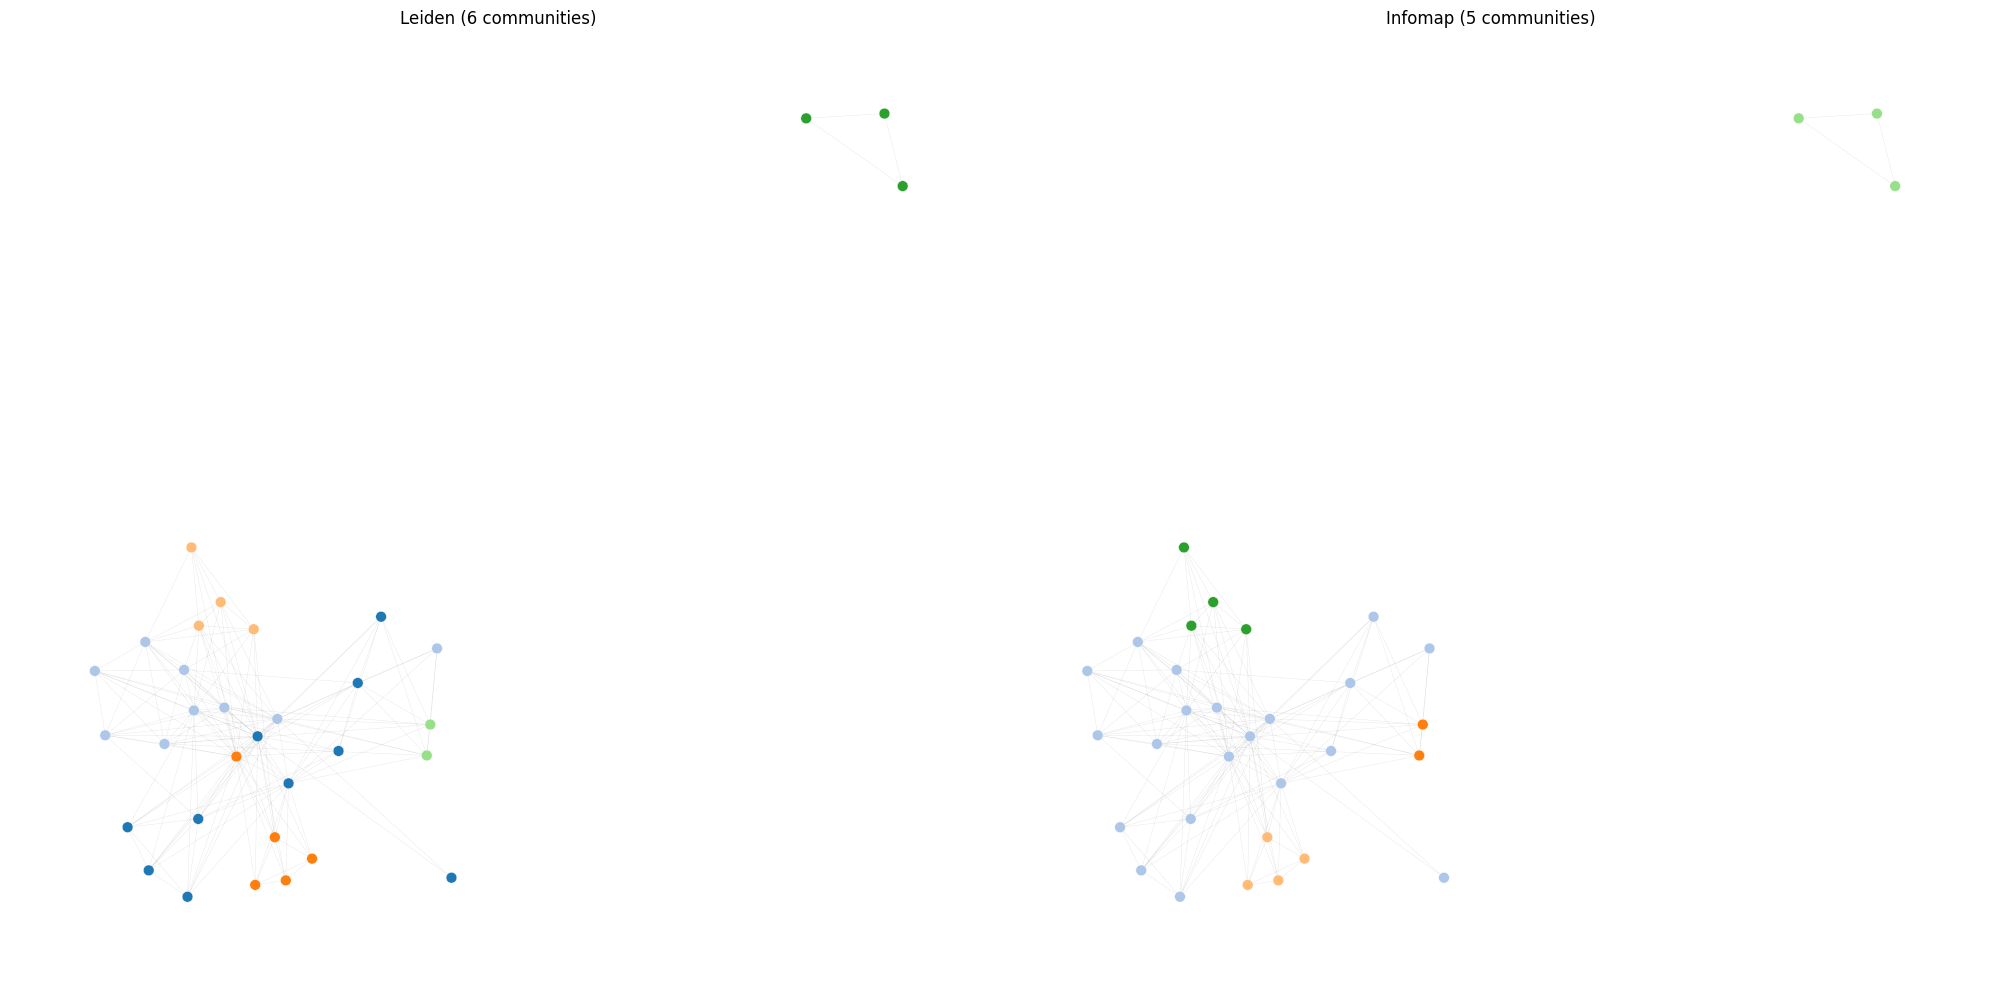

In [76]:
leiden_by_name = {(n.name() if hasattr(n, 'name') else str(n)): v
                  for n, v in modules_leiden.items()}

fig, axes = plt.subplots(1, 2, figsize=(20, 10))
for ax, (title, part) in zip(axes, [('Leiden', leiden_by_name),
                                     ('Infomap', infomap_by_name)]):
    colors = [plt.cm.tab20(part.get(n.name(), -1) % 20) for n in G.nodes()]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.1, width=0.3)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors,
                           node_size=60, edgecolors='white', linewidths=0.3)
    ax.set_title(f'{title} ({len(set(part.values()))} communities)')
    ax.axis('off')

plt.tight_layout()
plt.show()

Comment on communities:

In general, the two algorithms produce quite similar results:

* squinting as a separate community (predictably)
* the same edge communities:
  * 'beat.v.08', 'beat.v.15' together (this also appears reasonable)
  * 'foam.v.01', 'gleam.v.02', 'spark.v.02', 'sparkle.v.01' (shining, but somewhat distinct from flickering? And 'foam', which is hard to comment on)
  * 'dart.v.02', 'flash.v.02', 'flash.v.04', 'flaunt.v.01' (these (except 'flaunt') involve rapid movement)
(though Leiden adds 'flash.v.01' (the light sense) to it, while Infomap does not)


The main difference is that Leiden splits the largest community into two halves (broadly separating the verbs of blinking / eye movement from the verbs of flickering and twinkling), while Infomap does not. The result of Leiden seems to me more reasonable.



As compared to my previous work: these are largely novel and intruguing suggestions about the specifics and differences of light-related verbs; I have not focused on these specifics at all in my work (in part due to insufficiently detailed dictionary descriptions). That 'beat' verbs are separated from these 'light-related' verbs seems predictable.

## Step 5

**The plan**: If there appear to be sufficient data, try to study the more stable colexifications (by only including the colexifications if they pass some kind of threshold in terms of the number of lemmas with both meanings; again, I am not certain what that number would be, and would need to experiment). I am not at all certain there will be sufficient data due to the narrowness of the semantic domain though. (A digression from my project that appears interesting to me in this vein would be to investigate all verbs of closing in this manner; of course, that would be a separate project on its own).

I decided to use the synset list with 'close.v.01' included as a starting point, and to set a threshold of more than 4 shared lemmas.

In [111]:
lemmas_by_lang = {}
for lang in wn.langs():
  lemmas_total = []
  for s in relevant_list2:
    lemmas = [l.name() for l in wn.synset(s).lemmas(lang=lang)]
    if lemmas:  # only the non-empty ones
      lemmas_total.extend(sorted(set(lemmas)))
    lemmas_by_lang[lang] = sorted(set(lemmas_total))
len(lemmas_by_lang)
# print(len(lemmas_by_lang), lemmas_by_lang)

32

In [112]:
lemma2synsets = {}
for lang, lemmas in lemmas_by_lang.items():
  for lemma in lemmas:
    lemma2synsets[(lang, lemma)] = wn.synsets(lemma, lang=lang)
len(lemma2synsets)
# print(lemma2synsets)

235

In [113]:
synset_support = {} # Synset --> set of (lang, lemma)
for key, synsets in lemma2synsets.items():
  for s in synsets:
    synset_support.setdefault(s, set()).add(key)
print(len(synset_support))
# print(synset_support)

376


In [114]:
selected_synsets2 = sorted(
    [s for s, keys in synset_support.items() if len(keys) > 4],
    key=lambda s: s.name()
)
print(len(selected_synsets2))
# print(selected_synsets2)

43


In [99]:
selected_set2 = set(selected_synsets2)

In [115]:
synset2lemmas2 = {}
for s in selected_synsets2:
    L = set()
    for lang in wn.langs():
        for l in s.lemmas(lang=lang):
            L.add((lang, l.name()))
    synset2lemmas2[s] = L
# sanity check
some = selected_synsets2[0]
print(len(synset2lemmas2[some]))
print(synset2lemmas2[some])

126
{('arb', 'وضع_حد'), ('fin', 'tukkia_kulku'), ('arb', 'أربك'), ('nld', 'afzetten'), ('arb', 'اعترض'), ('slv', 'zapreti'), ('arb', 'حجز'), ('zsm', 'menghalangi'), ('hrv', 'blokirati'), ('zsm', 'membuntukan'), ('zsm', 'merebat'), ('ind', 'menggencat'), ('slv', 'ovirati'), ('ind', 'menghalang'), ('zsm', 'mengempang'), ('fin', 'estää'), ('ind', 'meredam'), ('ind', 'menghalang-halangi'), ('zsm', 'mendinding'), ('spa', 'bloquear'), ('fin', 'salvata'), ('fra', 'barrer'), ('arb', 'توقف_الطائرة'), ('ron', 'baricada'), ('ind', 'membantut'), ('ind', 'halangan'), ('ind', 'memegat'), ('ind', 'memandekkan'), ('arb', 'إعترض'), ('slk', 'blokovať'), ('ita', 'ostruire'), ('ind', 'membendung'), ('tha', 'ปิดถนน'), ('arb', 'إقتطع_مبلغا_مستحقا'), ('fra', 'arrêter'), ('eng', 'block_off'), ('zsm', 'mogok'), ('arb', 'أعاق'), ('arb', 'أوقف'), ('ind', 'melintangi'), ('eng', 'block'), ('ita', 'ingorgare'), ('ita', 'intasare'), ('arb', 'أقام_حاجِزا'), ('por', 'barricar'), ('arb', 'توقف_القطار'), ('arb', 'قطع'),

In [116]:
edges2 = {}
nodes2 = list(selected_synsets2)
for i in range(len(nodes2)):
    s1 = nodes2[i]
    for j in range(i+1, len(nodes2)):
        s2 = nodes2[j]
        inter = synset2lemmas2[s1].intersection(synset2lemmas2[s2])
        w = len(inter)
        if w > 0:
            edges2[(s1, s2)] = w
len(edges2)

450

In [117]:
#print(edges2)

In [118]:
G2 = nx.Graph()

for s in selected_synsets2:
  G2.add_node(s)
for (s1, s2), w in edges2.items():
    G2.add_edge(s1, s2, weight=w)

print(G2.number_of_nodes(), G2.number_of_edges())

43 450


In [119]:
isolates = list(nx.isolates(G2))
G2_noiso = G2.copy()
G2_noiso.remove_nodes_from(isolates)

print("G2 nodes/edges:", G2.number_of_nodes(), G2.number_of_edges())
print("isolates:", len(isolates))
print("G2_noiso nodes/edges:", G2_noiso.number_of_nodes(), G2_noiso.number_of_edges())

G2 nodes/edges: 43 450
isolates: 1
G2_noiso nodes/edges: 42 450


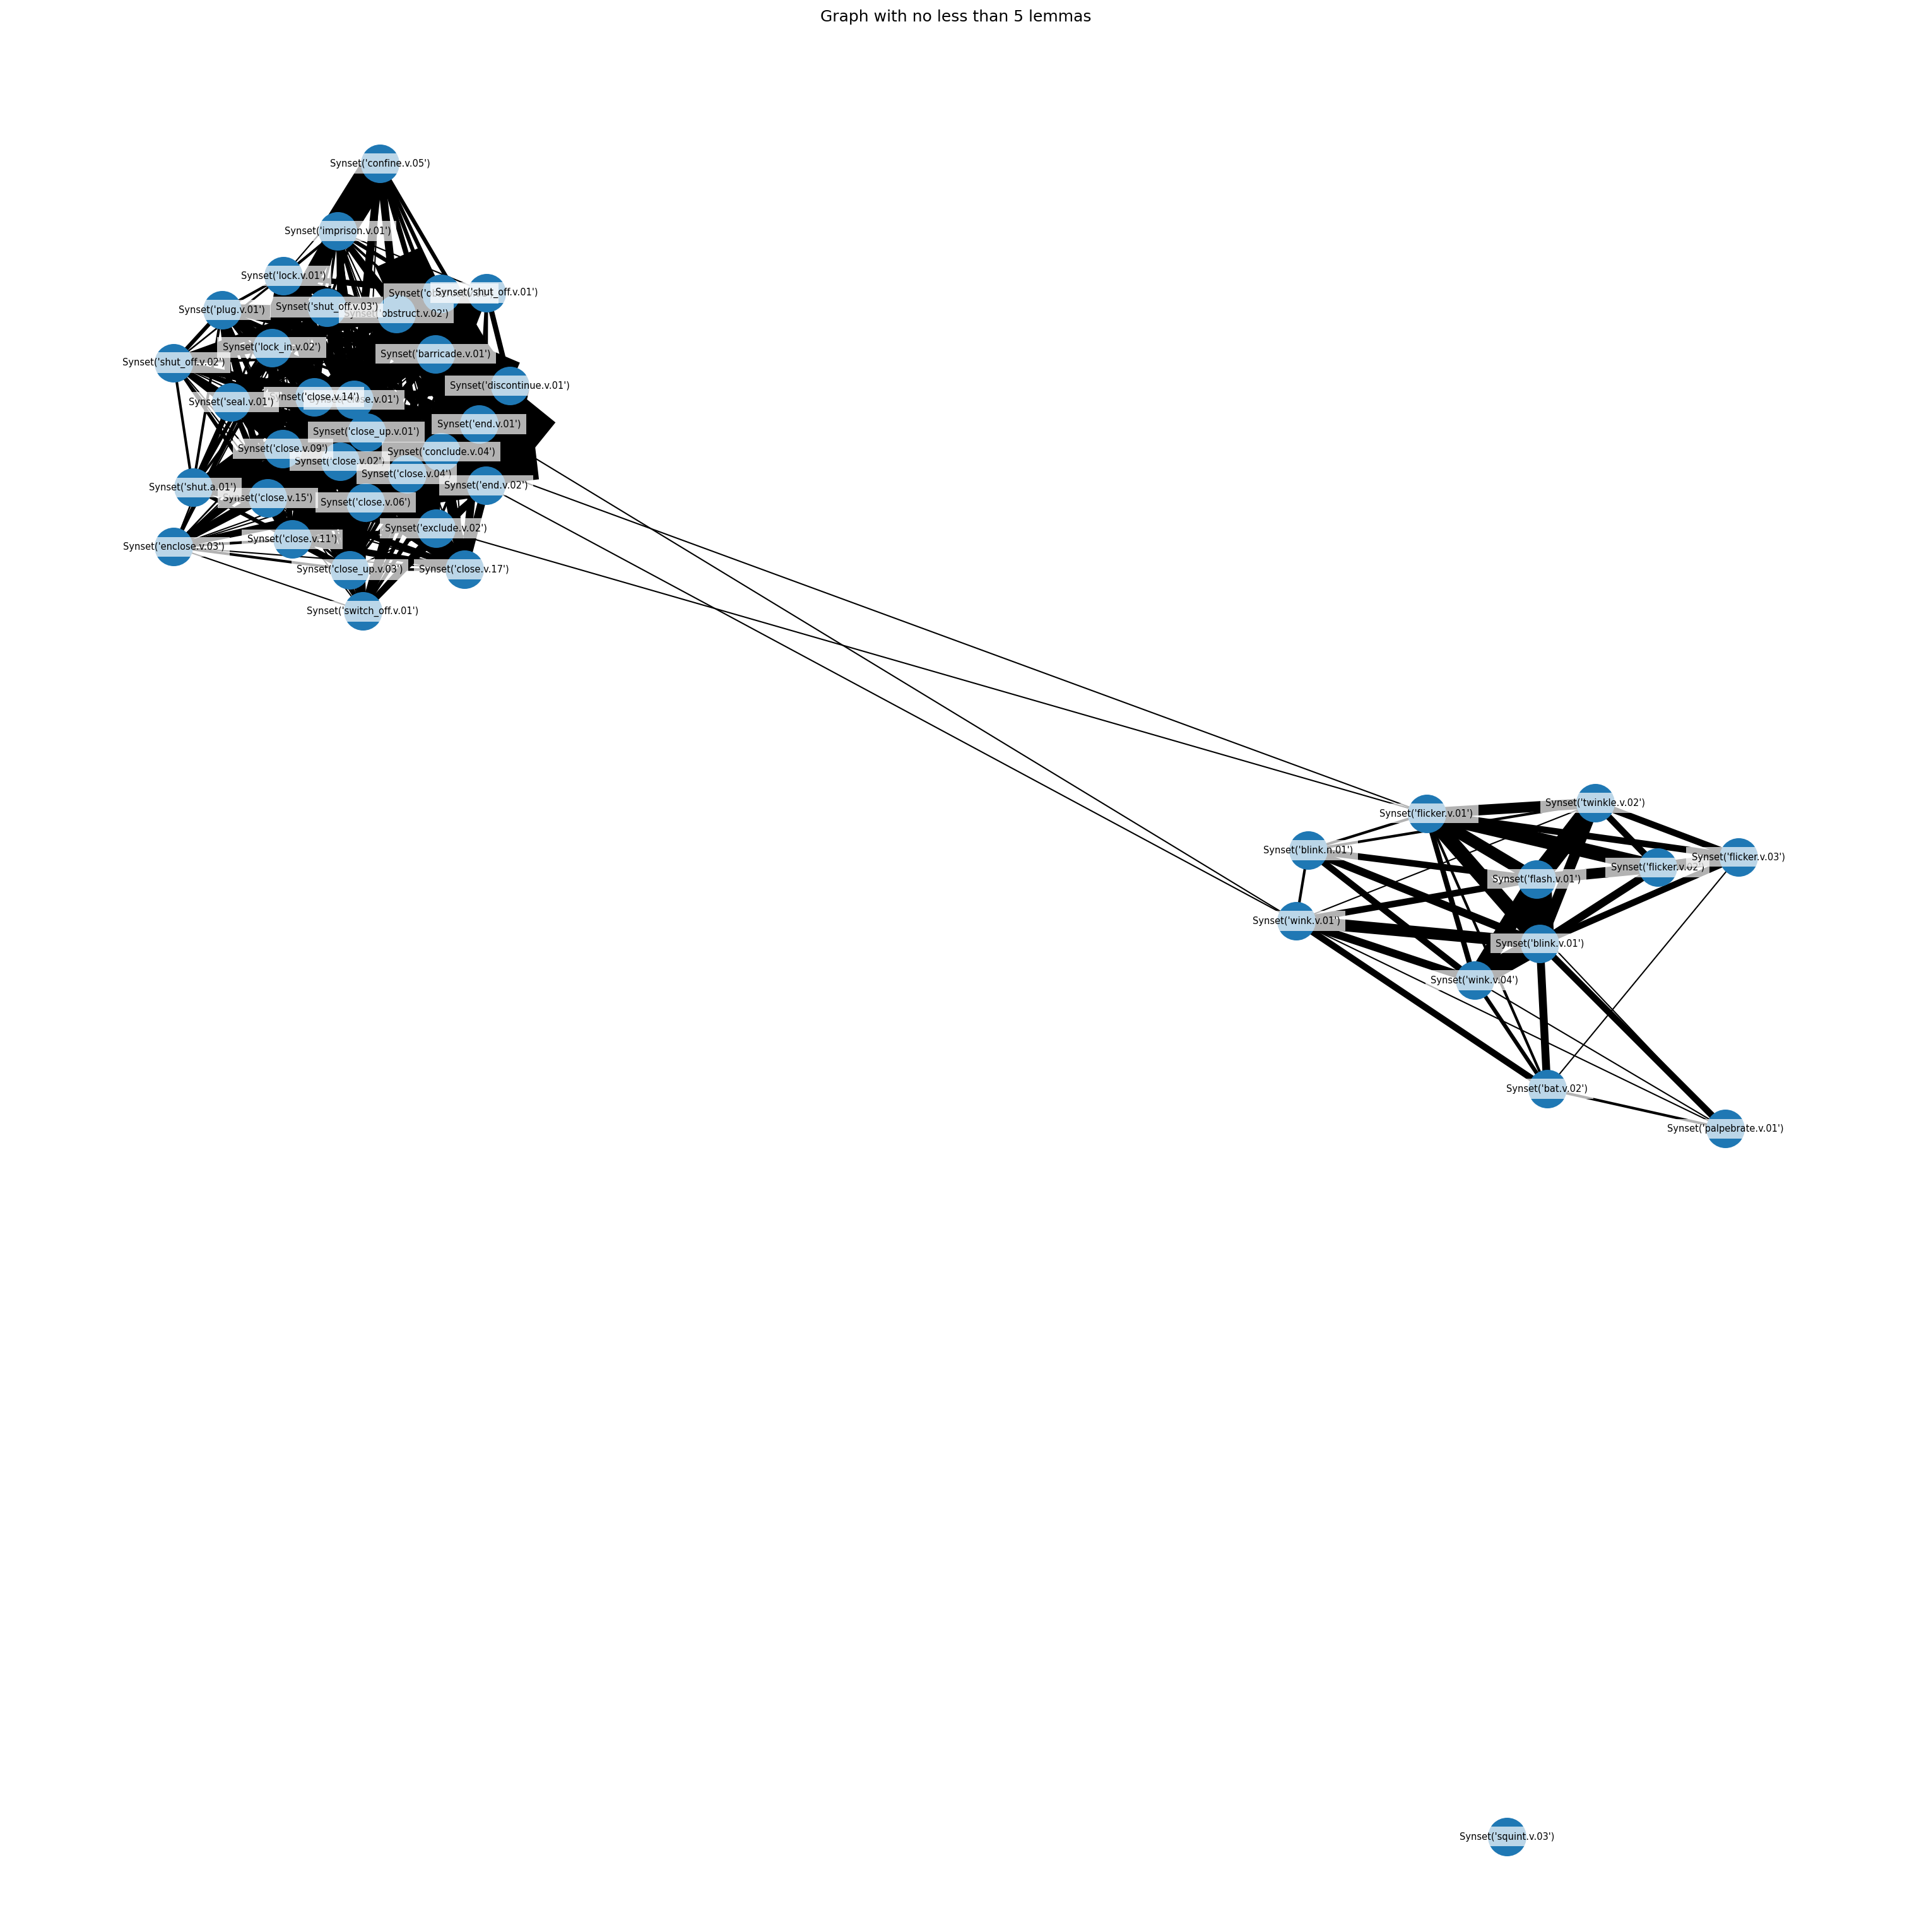

In [120]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 20), dpi=150)
pos2 = nx.spring_layout(G2, k=0.5, iterations=50, scale=2.0, seed=42)

weights = [G2[u][v]['weight'] for u, v in G2.edges()]

nx.draw(G2, pos2,
        node_size=800,
       width=weights)
nx.draw_networkx_labels(G2, pos2, font_size=7,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

plt.title("Graph with no less than 5 lemmas")
plt.show()

(Verbs of squinting are separate again...)

In [121]:
import numpy as np
import matplotlib.pyplot as plt
from networkx.algorithms import community

H = G2_noiso

components = list(nx.connected_components(H))
sizes = sorted([len(c) for c in components], reverse=True)
print("Connected components:", len(components))
print("Component sizes:", sizes)

print("Density:", nx.density(H))

deg = dict(H.degree())
wdeg = dict(H.degree(weight="weight"))

print("Degree min/mean/max:", np.min(list(deg.values())), np.mean(list(deg.values())), np.max(list(deg.values())))
print("Weighted degree min/mean/max:", np.min(list(wdeg.values())), np.mean(list(wdeg.values())), np.max(list(wdeg.values())))

deg_cent = nx.degree_centrality(H)
btw_cent = nx.betweenness_centrality(H)

def top10(d):
    return sorted(d.items(), key=lambda x: x[1], reverse=True)[:10]

print("\nTop degree centrality:")
for s, c in top10(deg_cent):
    print(s.name(), round(c, 3), "-", s.definition())

print("\nTop betweenness centrality:")
for s, c in top10(btw_cent):
    print(s.name(), round(c, 3), "-", s.definition())


Connected components: 1
Component sizes: [42]
Density: 0.5226480836236934
Degree min/mean/max: 5 21.428571428571427 30
Weighted degree min/mean/max: 10 126.66666666666667 374

Top degree centrality:
close.v.01 0.732 - move so that an opening or passage is obstructed; make shut
close_up.v.01 0.732 - cease to operate or cause to cease operating
barricade.v.01 0.707 - render unsuitable for passage
close.v.02 0.707 - become closed
close.v.04 0.707 - finish or terminate (meetings, speeches, etc.)
close.v.06 0.707 - complete a business deal, negotiation, or an agreement
close.v.09 0.707 - cause a window or an application to disappear on a computer desktop
close.v.14 0.707 - bar access to
conclude.v.04 0.707 - come to a close
end.v.01 0.707 - have an end, in a temporal, spatial, or quantitative sense; either spatial or metaphorical

Top betweenness centrality:
flicker.v.01 0.207 - move back and forth very rapidly
wink.v.01 0.138 - signal by winking
conclude.v.04 0.114 - come to a close
exclud

In [108]:
print(list(G2.neighbors(wn.synset('wink.v.01'))))
print(list(G2.neighbors(wn.synset('flicker.v.01'))))
print(list(G2.neighbors(wn.synset('close.v.01'))))

[Synset('bat.v.02'), Synset('blink.n.01'), Synset('blink.v.01'), Synset('end.v.01'), Synset('end.v.02'), Synset('flash.v.01'), Synset('palpebrate.v.01'), Synset('twinkle.v.02'), Synset('wink.v.04')]
[Synset('bat.v.02'), Synset('blink.n.01'), Synset('blink.v.01'), Synset('conclude.v.04'), Synset('exclude.v.02'), Synset('flash.v.01'), Synset('flicker.v.02'), Synset('flicker.v.03'), Synset('palpebrate.v.01'), Synset('twinkle.v.02'), Synset('wink.v.04')]
[Synset('barricade.v.01'), Synset('close.v.02'), Synset('close.v.04'), Synset('close.v.06'), Synset('close.v.09'), Synset('close.v.11'), Synset('close.v.14'), Synset('close.v.15'), Synset('close.v.17'), Synset('close_up.v.01'), Synset('close_up.v.03'), Synset('conclude.v.04'), Synset('confine.v.05'), Synset('discontinue.v.01'), Synset('enclose.v.03'), Synset('end.v.01'), Synset('end.v.02'), Synset('exclude.v.02'), Synset('imprison.v.01'), Synset('lock.v.01'), Synset('lock_in.v.02'), Synset('obstruct.v.01'), Synset('obstruct.v.02'), Synset(

Comment:
* the blinking and closing meanings are connected (the graph has one component) (in my data, I have seen colexifications between 'blink' and 'close the eyes'; here, however, the connection seems to be through other synsets, and at least 'close.v.01' is not directly connected to any of the blinking verbs)
* few of the colexifications of the blinking verbs are that common (some of the light-related ones surivive; this might be in part an artefact of the very specific meaning distinctions...)
* but the two sets (verbs of closing and verbs of blinking / flashing) form clear clusters on the graph
* the verbs of closing and their various colexifications are predictably more common and dominate the graph, justifying my decision not to include them in the main study

(Note: I did attempt a step 6 in which I would form a typological matrix & reduce it to two dimensions, but the results proved underwhelming, and I could not manage to achieve anything interesting or meaningful, so I decided not to include them)

# Conclusions

I have observed familiar colexification patterns (namely, verbs of blinking often also have meanings related to the flashing / flickering / twinkling of lights; WordNet classifies these meanings much more precisely than I do in my own work, and these meaning nuances may be worthy of additional consideration; out of rarer patterns, for instance, 'beat' and 'flutter', ocurring here, are familiar to me), as well as a few novel colexification patterns ('foam', 'dart' (as well as 'flicker' in the meaning of 'move rapidly'), 'flaunt').

My own data obtained from dictionaries predictably contain more colexification types that are not found here (though the once-occurring colexifications I did not include in the graph are worthy of additional consideration).

Interestingly, 'blink' (or 'wink', 'bat (eyelashes)', etc.) is not colexified with 'squint' anywhere in the WordNet database (although I have encountered such colexifications in my own data).

On the other hand, when closing verbs are included, the resulting graph has one component (though seemingly not from "close the eyes" + "blink" colexification either, although it is attested in my work). In any case, closing verbs, the closing domain being wider, overwhelm the graph, justifying my decision not to include them in the main part of the project; the absence of a particular 'close the eyes' meaning is a limitation as well.

Network analysis indicates the significance of some of these light-related meanings ('twinkle', 'flash'...) in terms of both weighted degree and betweenness centrality; splitting the graph into communities provides some additional suggestions on the particulars of these light-related verbs, which I had not previously considered in detail. A few meanings that are familiar to me, but did not occur many times in my own data are highlighted in these WordNet data ('gutter' ('burn unsteadily, feebly, or low') having high betweenness centrality, 'beat' having high weighted degree); additional investigation of these would be beneficial.
